# Лабораторная работа № 9. Линейная и логистическая регрессия

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Обучить и сравнить линейную и логистическую регрессию на данных о стекле, проанализировать коэффициенты и ошибки моделей.

## 1. Теоретическая часть

**1. Линейная регрессия** — модель вида ŷ = w₀ + w₁x₁ + … + wₚxₚ, решающая задачу регрессии (предсказание числового значения); параметры находят методом наименьших квадратов, минимизируя сумму квадратов ошибок.

**2. Логистическая регрессия** — линейная модель, у которой выход преобразуется сигмоидой (для многих классов — softmax) в вероятность принадлежности классу; решает задачу классификации и обучается максимизацией правдоподобия (минимизацией логистических потерь). От линейной отличается функцией потерь и выходом: вероятность вместо произвольного числа.

**3. Почему линейная регрессия не подходит для классификации?** Она выдаёт неограниченное число, а не вероятность; метки классов (1, 2, 3, 5, 6, 7) номинальные, а регрессия предполагает порядок и равные расстояния между ними; чувствительна к выбросам; квадратичная ошибка не соответствует задаче разделения классов.

**4. Коэффициент и свободный член.** Коэффициент wᵢ показывает, на сколько изменится предсказание при увеличении признака xᵢ на единицу при неизменных остальных (знак — направление влияния). Свободный член (intercept) w₀ — предсказание при всех признаках, равных нулю (для стандартизованных данных — предсказание для «среднего» объекта).

**5. Почему после масштабирования?** Регуляризация и численная оптимизация чувствительны к масштабу, а коэффициенты на разных шкалах несопоставимы: после стандартизации их модули можно сравнивать как важность признаков.

## 2. Практическая часть

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)
selected, SEL = select_glass(scaled)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_absolute_error, mean_squared_error)
X, y = selected[SEL], selected["Type"]
CLASSES = np.array(sorted(y.unique()))
def split(rs=42):
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
X_train, X_test, y_train, y_test = split(42)
print("Входная выборка (после отбора признаков):", selected.shape, "| признаки:", SEL)
print("train:", X_train.shape, "| test:", X_test.shape)
print("Классы в train:", y_train.value_counts().sort_index().to_dict(), "| в test:", y_test.value_counts().sort_index().to_dict())
def report(model, name, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    p = model.predict(Xte)
    return {"модель": name, "accuracy": accuracy_score(yte, p), "F1 macro": f1_score(yte, p, average="macro"),
            "F1 weighted": f1_score(yte, p, average="weighted")}

Входная выборка (после отбора признаков): (213, 7) | признаки: ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']
train: (170, 6) | test: (43, 6)
Классы в train: {1: 55, 2: 61, 3: 14, 5: 10, 6: 7, 7: 23} | в test: {1: 14, 2: 15, 3: 3, 5: 3, 6: 2, 7: 6}


### 2.1. Базовый уровень

In [ ]:
from sklearn.linear_model import LinearRegression, LogisticRegression
lin = LinearRegression().fit(X_train, y_train)
pred_lin = lin.predict(X_test)
print(f"LinearRegression (цель = числовой код Type): R2 = {r2_score(y_test, pred_lin):.3f}, MAE = {mean_absolute_error(y_test, pred_lin):.3f}, RMSE = {np.sqrt(mean_squared_error(y_test, pred_lin)):.3f}")
# метрики классификации для линейной регрессии: округляем предсказание до ближайшего существующего класса
to_cls = lambda p: CLASSES[np.abs(p[:, None] - CLASSES[None, :]).argmin(axis=1)]
pl = to_cls(pred_lin)
print(f"  как классификатор (ближайший класс): accuracy = {accuracy_score(y_test, pl):.3f}, F1 macro = {f1_score(y_test, pl, average='macro'):.3f}")

LinearRegression (цель = числовой код Type): R2 = 0.689, MAE = 0.900, RMSE = 1.190
  как классификатор (ближайший класс): accuracy = 0.395, F1 macro = 0.335


LogisticRegression: accuracy = 0.581, F1 macro = 0.567
                         precision    recall  f1-score   support

    окна зданий (float)       0.60      0.43      0.50        14
окна зданий (non-float)       0.45      0.60      0.51        15
      окна авто (float)       0.00      0.00      0.00         3
             контейнеры       1.00      0.67      0.80         3
                 посуда       0.50      1.00      0.67         2
                   фары       0.86      1.00      0.92         6

               accuracy                           0.58        43
              macro avg       0.57      0.62      0.57        43
           weighted avg       0.56      0.58      0.56        43



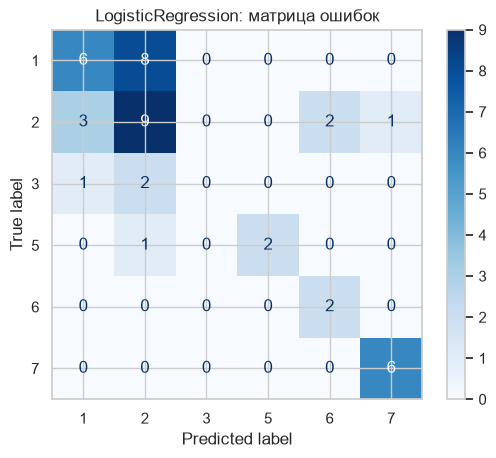

In [ ]:
logr = LogisticRegression(max_iter=3000).fit(X_train, y_train)
pred_log = logr.predict(X_test)
print(f"LogisticRegression: accuracy = {accuracy_score(y_test, pred_log):.3f}, F1 macro = {f1_score(y_test, pred_log, average='macro'):.3f}")
print(classification_report(y_test, pred_log, target_names=[TYPE_NAMES[k] for k in CLASSES], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_log, display_labels=CLASSES, cmap="Blues"); plt.title("LogisticRegression: матрица ошибок"); plt.show()

**Результат уровня 1.** Обе модели обучились без ошибок на подготовленных данных; метрики посчитаны. Логистическая регрессия как классификатор оказывается заметно корректнее: линейная регрессия вынуждена «вытягивать» классы вдоль одной числовой оси, хотя метки не упорядочены по смыслу.

### 2.2. Анализ коэффициентов

,коэфф. линейной регрессии
Mg,-1.336
Ca,-0.296
K,-0.118
Ba,0.083
Al,0.446
Na,0.497


intercept = 2.854


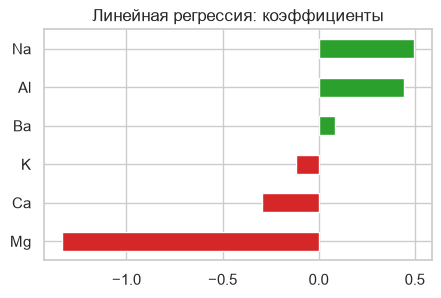

Наибольшее положительное влияние: Na | наибольшее отрицательное: Mg


In [ ]:
coef_lin = pd.Series(lin.coef_, index=SEL).sort_values()
display(coef_lin.round(3).to_frame("коэфф. линейной регрессии")); print("intercept =", round(lin.intercept_, 3))
coef_lin.plot.barh(color=["tab:red" if v < 0 else "tab:green" for v in coef_lin], figsize=(5, 3), title="Линейная регрессия: коэффициенты"); plt.show()
print("Наибольшее положительное влияние:", coef_lin.idxmax(), "| наибольшее отрицательное:", coef_lin.idxmin())

,Na,Mg,Al,K,Ca,Ba
класс 1,-0.83,1.33,-1.73,0.04,-0.19,-0.18
класс 2,-0.51,0.65,0.13,0.40,0.45,0.51
класс 3,0.22,0.91,-0.65,-0.29,-0.00,-0.03
класс 5,-0.83,-0.68,1.67,0.71,0.44,-0.02
класс 6,1.30,-0.60,0.10,-1.35,0.00,-0.88
класс 7,0.65,-1.61,0.47,0.50,-0.69,0.60


,средний |коэфф.| по классам
Mg,0.965
Al,0.792
Na,0.723
K,0.548
Ba,0.369
Ca,0.296


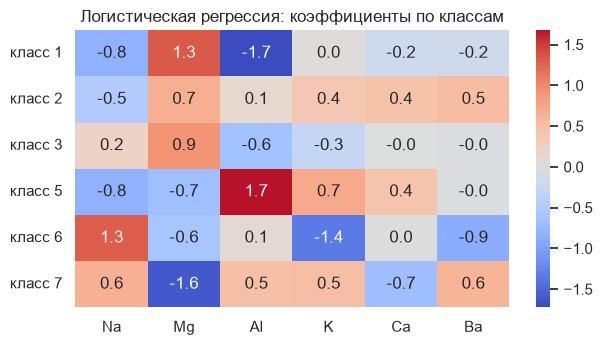

In [ ]:
cl = pd.DataFrame(logr.coef_, index=[f"класс {k}" for k in logr.classes_], columns=SEL)
display(cl.round(2))
imp = cl.abs().mean().sort_values(ascending=False)
display(imp.round(3).to_frame("средний |коэфф.| по классам"))
plt.figure(figsize=(7, 3.6)); sns.heatmap(cl, annot=True, fmt=".1f", cmap="coolwarm", center=0); plt.title("Логистическая регрессия: коэффициенты по классам"); plt.show()

**Ответы.** В линейной регрессии положительные коэффициенты (Na ≈ 0.50, Al ≈ 0.45, слабо Ba) увеличивают предсказанный код сорта, отрицательные (Mg ≈ −1.34, затем Ca, K) — уменьшают; значимость определяется модулем коэффициента (признаки стандартизованы). В логистической регрессии для каждого класса свой вектор коэффициентов: коэффициент — изменение *логарифма отношения шансов* класса относительно остальных при росте признака на 1σ, а не изменение значения целевой переменной; поэтому один и тот же признак может повышать вероятность одного класса и понижать другого (например, Mg повышает вероятность «окон» и снижает вероятность «фар»/«контейнеров», Ba и Al — наоборот). Сильнее всего на вероятности классов влияют признаки с наибольшим средним модулем коэффициентов (см. таблицу).

### 2.3. Сравнение предсказаний и истинных значений

,истина,linear,linear→класс,logistic
207,7,7.14,7,7
168,5,5.02,5,5
121,2,2.11,2,2
171,5,5.87,6,5
29,1,1.80,2,1
2,1,2.44,2,2
116,2,2.61,3,2
128,2,4.26,5,2
43,1,1.50,2,1
52,1,2.33,2,2


Ошибки линейной регрессии: среднее = 0.321, std = 1.146, макс. |ошибка| = 3.46


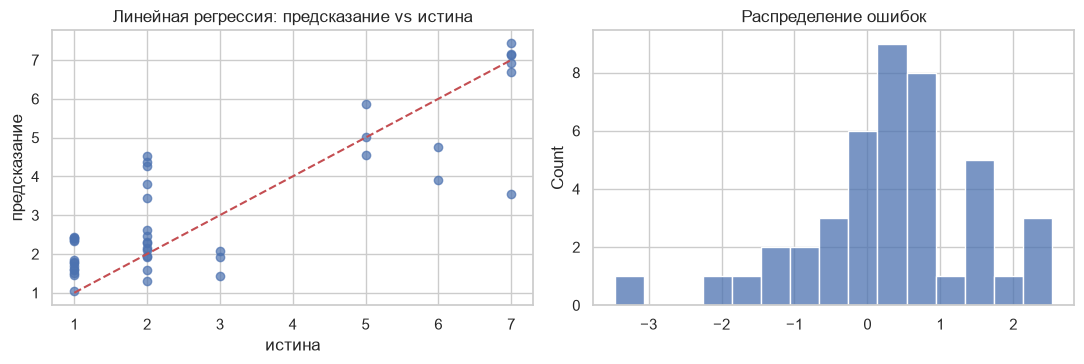

Ошибочных предсказаний логистической регрессии: 18 из 43


предсказано,1,2,5,6,7
истина,,,,,
1,6,8,0,0,0
2,3,9,0,2,1
3,1,2,0,0,0
5,0,1,2,0,0
6,0,0,0,2,0
7,0,0,0,0,6


In [ ]:
comp = pd.DataFrame({"истина": y_test.values, "linear": pred_lin.round(2), "linear→класс": pl, "logistic": pred_log}, index=y_test.index)
display(comp.head(12))
err = pred_lin - y_test.values
print(f"Ошибки линейной регрессии: среднее = {err.mean():.3f}, std = {err.std():.3f}, макс. |ошибка| = {np.abs(err).max():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(y_test, pred_lin, alpha=.7); ax[0].plot([1, 7], [1, 7], "r--"); ax[0].set_xlabel("истина"); ax[0].set_ylabel("предсказание"); ax[0].set_title("Линейная регрессия: предсказание vs истина")
sns.histplot(err, bins=15, ax=ax[1]); ax[1].set_title("Распределение ошибок"); plt.tight_layout(); plt.show()
# ошибки классификации по классам
wrong = comp[comp["logistic"] != comp["истина"]]
print("Ошибочных предсказаний логистической регрессии:", len(wrong), "из", len(comp))
display(pd.crosstab(comp["истина"], comp["logistic"], rownames=["истина"], colnames=["предсказано"]))

In [ ]:
proba = logr.predict_proba(X_test); conf = proba.max(axis=1); ok = pred_log == y_test.values
print("Высокая уверенность (>0.9):", int((conf > 0.9).sum()), "объектов; из них верных:", int(((conf > 0.9) & ok).sum()))
tab = X_test.copy(); tab["истина"] = y_test.values; tab["предсказано"] = pred_log; tab["уверенность"] = conf.round(3)
print("\nУверенные и верные (топ-4):"); display(tab[ok].sort_values("уверенность", ascending=False).head(4))
print("Неверно классифицированные:"); display(tab[~ok].sort_values("уверенность", ascending=False))
print("Средние значения признаков: верные vs неверные"); display(pd.DataFrame({"верные": tab[ok][SEL].mean(), "неверные": tab[~ok][SEL].mean()}).round(2).T)

Высокая уверенность (>0.9): 3 объектов; из них верных: 3

Уверенные и верные (топ-4):


,Na,Mg,Al,K,Ca,Ba,истина,предсказано,уверенность
202,1.713320,-1.860172,1.092483,-0.765554,-0.473863,3.086325,7,7,0.988
193,1.418748,-1.860172,1.072271,-0.765554,-0.305150,2.804676,7,7,0.979
171,-0.495966,-1.860172,3.174302,8.764103,-1.422876,-0.353808,5,5,0.933
198,1.971070,-1.860172,2.143498,-0.688826,-0.087228,0.712432,7,7,0.880


Неверно классифицированные:


,Na,Mg,Al,K,Ca,Ba,истина,предсказано,уверенность
151,0.289558,0.674026,-1.615903,-0.673480,-0.016931,-0.353808,3,1,0.809
140,-0.250489,0.660140,-0.767006,0.109149,-0.382476,-0.172748,2,1,0.631
113,-0.373227,0.896202,-0.524464,0.155186,-0.368417,-0.353808,2,1,0.606
60,0.498213,0.625425,-0.261710,-0.581406,-0.199704,1.034316,1,2,0.578
20,-0.716894,0.604596,0.081891,0.063112,-0.305150,-0.353808,1,2,0.559
52,-0.324132,0.111642,-0.342557,0.078457,0.081485,-0.353808,1,2,0.520
37,-0.815085,0.555995,-0.201075,0.216568,-0.192674,-0.353808,1,2,0.485
2,0.154546,0.604596,0.182950,-0.167073,-0.825349,-0.353808,1,2,0.480
147,-0.201394,0.618482,-0.140439,0.093803,-0.361387,-0.353808,3,2,0.479
23,-0.729168,0.618482,-0.201075,0.185877,-0.255941,-0.353808,1,2,0.468


Средние значения признаков: верные vs неверные


,Na,Mg,Al,K,Ca,Ba
верные,0.18,-0.47,0.37,0.14,0.10,0.16
неверные,0.05,0.27,-0.30,-0.05,-0.13,-0.27


In [ ]:
rows = []
for rs in [0, 1, 7, 42, 123]:
    Xtr, Xte, ytr, yte = split(rs)
    lg = LogisticRegression(max_iter=3000).fit(Xtr, ytr); ln = LinearRegression().fit(Xtr, ytr)
    rows.append({"random_state": rs, "logreg accuracy": accuracy_score(yte, lg.predict(Xte)), "logreg F1 macro": f1_score(yte, lg.predict(Xte), average="macro"),
                 "linear R2": r2_score(yte, ln.predict(Xte)), **{f"w_{f}": ln.coef_[i] for i, f in enumerate(SEL)}})
st = pd.DataFrame(rows).set_index("random_state")
display(st.round(3)); print("Разброс (std) метрик:"); display(st.std().round(3).to_frame("std").T)

,logreg accuracy,logreg F1 macro,linear R2,w_Na,w_Mg,w_Al,w_K,w_Ca,w_Ba
random_state,,,,,,,,,
0,0.605,0.489,0.716,0.437,-1.344,0.503,-0.215,-0.342,-0.002
1,0.628,0.618,0.843,0.437,-1.317,0.425,-0.150,-0.390,0.143
7,0.674,0.618,0.559,0.543,-1.097,0.650,-0.263,-0.216,0.119
42,0.581,0.567,0.689,0.497,-1.336,0.446,-0.118,-0.296,0.083
123,0.628,0.536,0.808,0.391,-1.369,0.317,-0.167,-0.506,0.197


Разброс (std) метрик:


,logreg accuracy,logreg F1 macro,linear R2,w_Na,w_Mg,w_Al,w_K,w_Ca,w_Ba
std,0.034,0.055,0.111,0.059,0.111,0.122,0.057,0.108,0.074


### Вывод

Линейная регрессия предполагает линейную зависимость целевой переменной от признаков, независимость и нормальность ошибок, отсутствие сильной мультиколлинеарности и постоянство дисперсии ошибок; логистическая регрессия предполагает линейность логарифма отношения шансов от признаков и независимость наблюдений. Линейные модели хорошо работают, когда зависимость близка к линейной, классы приблизительно линейно разделимы, признаки масштабированы, а выборка не слишком мала по сравнению с числом признаков. На данных о стекле логистическая регрессия достигает точности порядка 0.58–0.67 в зависимости от random_state (на основном разбиении 0.58); уверенно распознаёт «фары» (F1 ≈ 0.92) и «контейнеры», путает между собой два вида строительных окон и совсем не находит окна авто (3 объекта в тесте), которые перекрываются с окнами зданий в пространстве признаков. Линейная регрессия на кодах классов даёт R² ≈ 0.69 как регрессия, но как классификатор — всего 0.40 точности и систематические ошибки, так как коды 1, 2, 3, 5, 6, 7 номинальные и не образуют линейной шкалы, поэтому она непригодна как классификатор для этой задачи. Изменение random_state заметно меняет метрики (std accuracy ≈ 0.03, R² — до 0.11 из-за малой выборки и малых классов), а знаки главных коэффициентов (Mg — отрицательный, Na и Al — положительные) остаются стабильными, поэтому такая интерпретация устойчива; слабые коэффициенты (Ba, K) меняют величину и даже знак. Ошибки логистической регрессии сосредоточены в похожих по составу сортах, а объекты с высокой уверенностью почти всегда классифицируются верно. Тем не менее линейные модели — важный базовый этап: они быстры, интерпретируемы и задают нижнюю границу качества, с которой сравниваются более сложные модели следующих лабораторных работ (Bayes, kNN, деревья, лес).